<a href="https://colab.research.google.com/github/Prakash9188/Prakash9188/blob/main/NeuralNetwork.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import torch
from torchvision import datasets , transforms
from torch.utils.data import DataLoader
import torch.nn as nn
import matplotlib.pyplot as plt


In [6]:
transforms = transforms.ToTensor()

In [7]:
train_data = datasets.MNIST(
    root = "./data" ,
    download = True ,
    train = True ,
    transform = transforms
)


100%|██████████| 9.91M/9.91M [00:00<00:00, 137MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 13.7MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 58.2MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 5.36MB/s]


In [8]:
test_data = datasets.MNIST(
    root = "./data" ,
    download = True ,
    train = False ,
    transform = transforms
)

In [12]:
trainloader = DataLoader(
    train_data ,
    shuffle=True ,
    batch_size=10
)



In [14]:
testloader = DataLoader(
     test_data ,
    batch_size=64
)

In [15]:
images  ,label = train_data[0]
print("image shape" , images.shape)


image shape torch.Size([1, 28, 28])


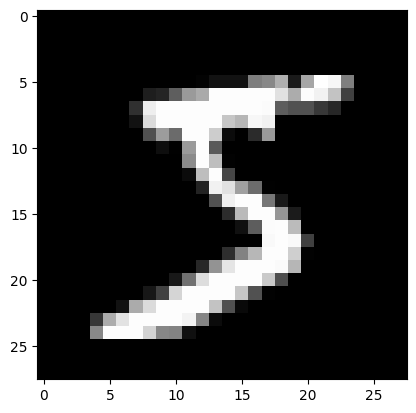

In [20]:
plt.imshow(images.squeeze() , cmap='gray')
plt.show()

In [25]:
from torch.nn.modules.linear import Linear
cnn = nn.Sequential(
nn.Conv2d(1,8,kernel_size=3,padding=1),

nn.ReLU(),
nn.MaxPool2d(2),
nn.Flatten(),
nn.Linear(8*14*14 ,10)
)

In [26]:
epochs = 3

In [28]:
from torch.optim import Adam

In [29]:
optimizer = Adam(cnn.parameters() , lr=0.001)


In [30]:
loss_fn = nn.CrossEntropyLoss()

In [31]:
for epoch in range(epochs):
  for images , labels in trainloader :

    outputs = cnn(images)
    loss = loss_fn(outputs , labels)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
  print("epoch , loss"  , epoch , loss.item())


epoch , loss 0 0.8972261548042297
epoch , loss 1 0.03995317965745926
epoch , loss 2 0.0656464695930481


In [33]:
images , labels = next(iter( testloader))

with torch.no_grad() :
  predictions = cnn(images)

predictions_x = predictions.argmax(dim=1)
print(labels)

tensor([7, 2, 1, 0, 4, 1, 4, 9, 5, 9, 0, 6, 9, 0, 1, 5, 9, 7, 3, 4, 9, 6, 6, 5,
        4, 0, 7, 4, 0, 1, 3, 1, 3, 4, 7, 2, 7, 1, 2, 1, 1, 7, 4, 2, 3, 5, 1, 2,
        4, 4, 6, 3, 5, 5, 6, 0, 4, 1, 9, 5, 7, 8, 9, 3])


In [34]:
print(predictions_x)

tensor([7, 2, 1, 0, 4, 1, 4, 9, 5, 9, 0, 6, 9, 0, 1, 5, 9, 7, 5, 4, 9, 6, 6, 5,
        4, 0, 7, 4, 0, 1, 3, 1, 3, 4, 7, 2, 7, 1, 2, 1, 1, 7, 4, 2, 3, 5, 1, 2,
        4, 4, 6, 3, 5, 5, 6, 0, 4, 1, 9, 5, 7, 8, 5, 3])


In [36]:
encoder =  nn.Sequential(
    nn.Flatten(),
    nn.Linear(784,64),
    nn.ReLU()
)

In [37]:
decoder = nn.Sequential(
    nn.Linear(64,784),
    nn.Sigmoid()

)

In [38]:
ae = nn.Sequential(encoder ,decoder)

In [40]:
loss_fn = nn.MSELoss()

In [42]:
from torch._higher_order_ops.invoke_leaf_function import reconstruct_original_args
for epoch in range(epochs):
  for images , _ in trainloader :
    reconstructed = ae(images)
    original = images.view(-1,784)

    loss  = loss_fn(reconstructed , original)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

  print("epoch , loss"  , epoch , loss.item())

epoch , loss 0 0.23025241494178772
epoch , loss 1 0.23412847518920898
epoch , loss 2 0.23156428337097168


In [43]:
images ,labels = next(iter(testloader))
with torch.no_grad() :
  reconstructed = ae(images)



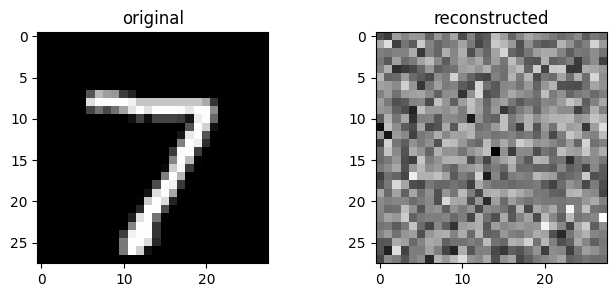

In [47]:
plt.figure(figsize=(8,3))

plt.subplot(1,2,1)
plt.imshow(images[0].squeeze() , cmap='gray')
plt.title("original")

plt.subplot(1,2,2)
plt.imshow(reconstructed[0].view(28,28) , cmap='gray')
plt.title("reconstructed")

plt.show()